<a href="https://colab.research.google.com/github/shashikawka/268452H-CS5998-Capstone-Project/blob/main/04_autoencoder_anomaly_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Temporal Autoencoder for Anomaly Detection

This notebook implements a window based autoencoder for detecting
unusual behaviour in the MetroPT-3 railway APU sensor dataset.

The model uses windows of 60 observations with 15 sensor features.

I used the pre-failure data for training and the validation data to select the model settings and anomaly threshold. The evaluation data is kept separately to test how well the model performs.

###Step 1 : Data Preperation

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import tensorflow as tf

from pathlib import Path
from tensorflow.keras import layers, models

tf.keras.utils.set_random_seed(42) # Reproducibility

print("TensorFlow version:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.21.0
GPUs: []


In [6]:
#Load data

data_dir = Path('/content/drive/MyDrive/CAPSTONE_PROJECT/processed_data')

# Load temporal windows
X_train_windows = np.load(
    data_dir / 'X_train_windows.npy',
    mmap_mode='r'
)

X_val_windows = np.load(
    data_dir / 'X_val_windows.npy',
    mmap_mode='r'
)

X_eval_windows = np.load(
    data_dir / 'X_eval_windows.npy',
    mmap_mode='r'
)

print("Training window:", X_train_windows.shape)
print("Validation window:", X_val_windows.shape)
print("Evaluation window:", X_eval_windows.shape)

print("\nData type:", X_train_windows.dtype)

Training window: (41938, 60, 15)
Validation window: (13749, 60, 15)
Evaluation window: (94307, 60, 15)

Data type: float32


In [ ]:
#Verify the window data
print("Training shape valid:",
      X_train_windows.shape[1:] == (60, 15))

print("Validation shape valid:",
      X_val_windows.shape[1:] == (60, 15))

print("Evaluation shape valid:",
      X_eval_windows.shape[1:] == (60, 15))

print("\nFirst training window:", X_train_windows[0].shape)

print("Training values finite:",
      np.isfinite(X_train_windows).all())

print("Validation values finite:",
      np.isfinite(X_val_windows).all())

print("Evaluation values finite:",
      np.isfinite(X_eval_windows).all())

Training shape valid: True
Validation shape valid: True
Evaluation shape valid: True

First training window: (60, 15)
Training values finite: True
Validation values finite: True
Evaluation values finite: True


###Step 2 : Build the Autoencoder Architecture

In [ ]:
#2.1 Cereate Auto Encoder
#simple dense autoencoder. It uses all observations within a window, but it does not explicitly model sequence order like an LSTM.
# Each window contains 60 observations and 15 features
window_size = X_train_windows.shape[1]
n_features = X_train_windows.shape[2]

input_dim = window_size * n_features

# Build the autoencoder
autoencoder = models.Sequential([
    layers.Input(shape=(window_size, n_features)),

    # Convert the window into a single vector
    layers.Flatten(),

    # Encoder
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),

    # Bottleneck
    layers.Dense(32, activation='relu'),

    # Decoder
    layers.Dense(64, activation='relu'),
    layers.Dense(128, activation='relu'),
    layers.Dense(input_dim, activation='linear'),

    # Restore the original window shape
    layers.Reshape((window_size, n_features))
])

# Configure the model
autoencoder.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='mse'
)

# Display the architecture
autoencoder.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 900)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       115,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 900)            │       116,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 60, 15)         │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 252,196 (985.14 KB)

 Trainable params: 252,196 (985.14 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#2.2 Create a model
# Test the model using one training window
sample_window = np.asarray(X_train_windows[:1])

reconstructed_window = autoencoder.predict(
    sample_window,
    verbose=0
)

print("Original window shape:", sample_window.shape)
print("Reconstructed window shape:", reconstructed_window.shape)

Original window shape: (1, 60, 15)
Reconstructed window shape: (1, 60, 15)


##### OBSERVATION:
##### I created a dense autoencoder using the 60 observation windows.
##### Each window has 15 sensor features, giving 900 input values.
##### The encoder reduces these values to a 32-value bottleneck,
##### and the decoder tries to reconstruct the original window.
##### I used MSE to measure the reconstruction error.
##### The model has not been trained yet.

###Step 3 : Train the Autoencoder

In [ ]:
#3.1 train the model
# Stop training if validation loss does not improve for 5 epochs
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

# Train the autoencoder
history = autoencoder.fit(
    X_train_windows,
    X_train_windows,
    validation_data=(X_val_windows, X_val_windows),
    epochs=30,
    batch_size=256,
    shuffle=True,
    callbacks=[early_stopping],
    verbose=1
)

print("\nAutoencoder training completed.")
print("Epochs completed:", len(history.history['loss']))
print("Best validation loss:", min(history.history['val_loss']))

Epoch 1/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - loss: 0.1914 - val_loss: 0.1709
Epoch 2/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.0756 - val_loss: 0.1405
Epoch 3/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 4s 27ms/step - loss: 0.0666 - val_loss: 0.1308
Epoch 4/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - loss: 0.0628 - val_loss: 0.1311
Epoch 5/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.0601 - val_loss: 0.1271
Epoch 6/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.0576 - val_loss: 0.1263
Epoch 7/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - loss: 0.0556 - val_loss: 0.1212
Epoch 8/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.0536 - val_loss: 0.1193
Epoch 9/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.0518 - val_loss: 0.1163
Epoch 10/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.0502 - val_loss: 0.1159
Epoch 11/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 7s 28ms/step - loss: 0.0487 - val_loss: 0.1105
Epoch 12/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 

##### OBSERVATIONS:
##### I trained the autoencoder using the training windows and used the validation windows to monitor its reconstruction loss.
##### I set the maximum training epochs to 30 and used early stopping to stop training if the validation loss did not improve.
##### After training, I will compare the training and validation loss curves to check how well the model learned.

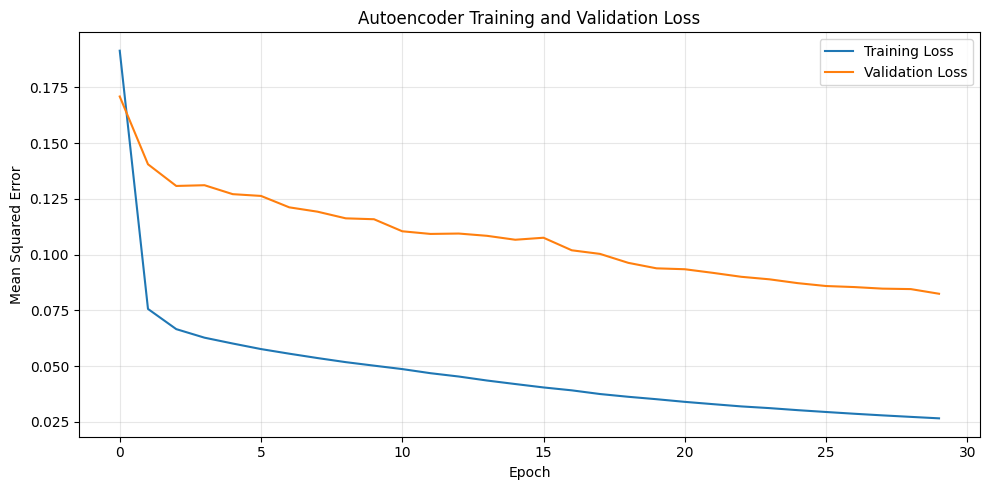

<Figure size 640x480 with 0 Axes>

In [ ]:
#3.2 Visualize training and validation loss
plt.figure(figsize=(10, 5))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.title('Autoencoder Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Mean Squared Error')
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

plt.savefig(
    '/content/drive/MyDrive/CAPSTONE_PROJECT/04_autoecoder/Autoencoder_Training_And_Valisation_Loss.png',
    dpi=300,
    bbox_inches='tight'
)

##### OBESERVATIONS:
##### The autoencoder completed all 30 training epochs. The training loss decreased from 0.0260 to 0.0189.
##### The validation loss also decreased, with the lowest value of 0.0675 recorded at epoch 29.
##### The validation loss remained higher than the training loss.
##### This may be due to differences in sensor behaviour between the training and validation periods.
##### Further evaluation is needed to check anomaly detection performance.

In [ ]:
#3.3 Continue training for up to 20 more epochs

# Continue training the existing autoencoder
additional_history = autoencoder.fit(
    X_train_windows,
    X_train_windows,
    validation_data=(X_val_windows, X_val_windows),
    epochs=20,
    batch_size=256,
    shuffle=True,
    callbacks=[early_stopping],
    verbose=1
)

print("\nAdditional training completed.")
print("Additional epochs:", len(additional_history.history['loss']))
print("Best additional validation loss:",
      min(additional_history.history['val_loss']))

Epoch 1/20
164/164 ━━━━━━━━━━━━━━━━━━━━ 4s 27ms/step - loss: 0.0260 - val_loss: 0.0803
Epoch 2/20
164/164 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - loss: 0.0255 - val_loss: 0.0792
Epoch 3/20
164/164 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - loss: 0.0248 - val_loss: 0.0791
Epoch 4/20
164/164 ━━━━━━━━━━━━━━━━━━━━ 8s 38ms/step - loss: 0.0244 - val_loss: 0.0778
Epoch 5/20
164/164 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.0239 - val_loss: 0.0776
Epoch 6/20
164/164 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.0235 - val_loss: 0.0778
Epoch 7/20
164/164 ━━━━━━━━━━━━━━━━━━━━ 7s 30ms/step - loss: 0.0231 - val_loss: 0.0769
Epoch 8/20
164/164 ━━━━━━━━━━━━━━━━━━━━ 4s 21ms/step - loss: 0.0227 - val_loss: 0.0771
Epoch 9/20
164/164 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - loss: 0.0224 - val_loss: 0.0766
Epoch 10/20
164/164 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.0220 - val_loss: 0.0763
Epoch 11/20
164/164 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.0218 - val_loss: 0.0748
Epoch 12/20
164/164 ━━━━━━━━━━━━━━━━━━━━ 

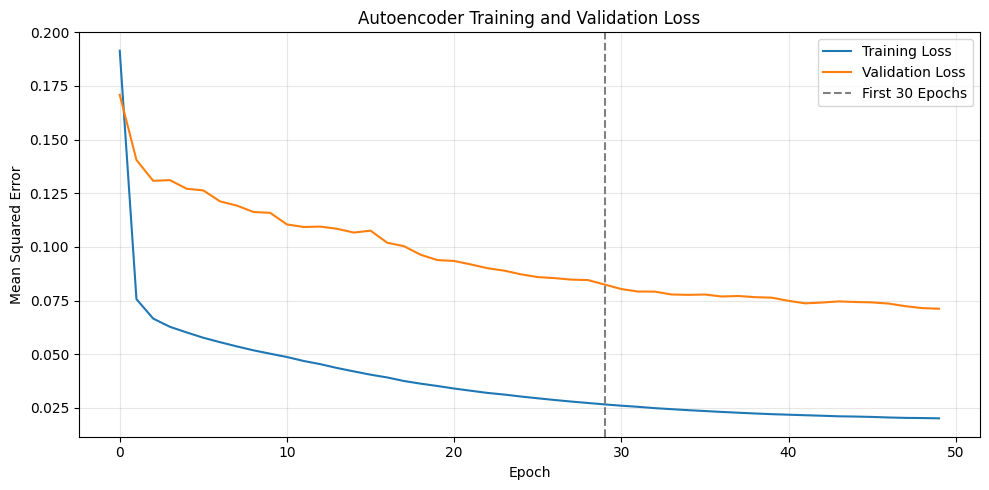

Total epochs: 50
Best validation loss: 0.07117723673582077


In [ ]:
#3.4 Plot the complete training history

# Combine the original and additional training results
all_train_loss = (
    history.history['loss'] +
    additional_history.history['loss']
)

all_val_loss = (
    history.history['val_loss'] +
    additional_history.history['val_loss']
)

plt.figure(figsize=(10, 5))

plt.plot(all_train_loss, label='Training Loss')
plt.plot(all_val_loss, label='Validation Loss')

plt.axvline(
    x=29,
    color='gray',
    linestyle='--',
    label='First 30 Epochs'
)

plt.title('Autoencoder Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Mean Squared Error')
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Total epochs:", len(all_train_loss))
print("Best validation loss:", min(all_val_loss))

##### OBSERVATIONS:
##### I first trained the autoencoder for 30 epochs.
##### Since the validation loss was still decreasing, I continued training for another 20 epochs.
##### The validation loss improved from 0.0825 to 0.0712. The training loss also decreased to around 0.0201.
##### The validation loss is still higher than the training loss. I will now evaluate the model using reconstruction errors.

###Step 5: Save trained model

In [ ]:
from pathlib import Path
import json

# Create a folder for autoencoder results
autoencoder_dir = data_dir.parent / 'autoencoder_results'
autoencoder_dir.mkdir(parents=True, exist_ok=True)

# Save the trained model
autoencoder.save(autoencoder_dir / 'autoencoder_model.keras')

# Save training history
training_history = {
    'loss': [float(x) for x in all_train_loss],
    'val_loss': [float(x) for x in all_val_loss]
}

with open(autoencoder_dir / 'training_history.json', 'w') as f:
    json.dump(training_history, f, indent=4)

print("Model saved:", autoencoder_dir / 'autoencoder_model.keras')
print("Training history saved successfully.")

Model saved: /content/drive/MyDrive/CAPSTONE_PROJECT/autoencoder_results/autoencoder_model.keras
Training history saved successfully.


###Step 5: Verify saved model

In [ ]:
# Load the saved model
loaded_autoencoder = tf.keras.models.load_model(
    autoencoder_dir / 'autoencoder_model.keras'
)

# Check its output shape
sample = np.asarray(X_val_windows[:1])

prediction = loaded_autoencoder.predict(
    sample,
    verbose=0
)

print("Input shape:", sample.shape)
print("Output shape:", prediction.shape)
print("Model loaded successfully.")

Input shape: (1, 60, 15)
Output shape: (1, 60, 15)
Model loaded successfully.


##### OBSERVATIONS:
##### I saved the trained autoencoder and its training history
##### to Google Drive so I can reuse them without retraining.
##### I also loaded the saved model and checked its output shape.

###Step 6 : Calculate Reconstruction Errors

In [17]:
#4.1 Calculate Reconstruction Erorrs
def calculate_reconstruction_errors(model, windows, batch_size=256):

    errors = []

    for start in range(0, len(windows), batch_size):

        batch = np.asarray(
            windows[start:start + batch_size]
        )

        reconstructed = model.predict(
            batch,
            verbose=0
        )

        batch_errors = np.mean(
            (batch - reconstructed) ** 2,
            axis=(1, 2)
        )

        errors.append(batch_errors)

    return np.concatenate(errors)


# Calculate reconstruction errors
train_errors = calculate_reconstruction_errors(
    autoencoder, X_train_windows
)

val_errors = calculate_reconstruction_errors(
    autoencoder, X_val_windows
)

eval_errors = calculate_reconstruction_errors(
    autoencoder, X_eval_windows
)

print("Training errors:", train_errors.shape)
print("Validation errors:", val_errors.shape)
print("Evaluation errors:", eval_errors.shape)

Training errors: (41938,)
Validation errors: (13749,)
Evaluation errors: (94307,)


In [ ]:
autoencoder = tf.keras.models.load_model(
    autoencoder_dir / 'autoencoder_model.keras'
)

###Step 7 : Analyze Reconstruction Errors

In [14]:
auto_encoder_dir = Path('/content/drive/MyDrive/CAPSTONE_PROJECT/autoencoder_results')
data_dir = Path('/content/drive/MyDrive/CAPSTONE_PROJECT/processed_data')

In [15]:
autoencoder = tf.keras.models.load_model(
    autoencoder_dir / 'autoencoder_model.keras'
)

In [16]:
X_train_windows = np.load(
    data_dir / 'X_train_windows.npy',
    mmap_mode='r'
)

X_val_windows = np.load(
    data_dir / 'X_val_windows.npy',
    mmap_mode='r'
)

X_eval_windows = np.load(
    data_dir / 'X_eval_windows.npy',
    mmap_mode='r'
)

print("Training:", X_train_windows.shape)
print("Validation:", X_val_windows.shape)
print("Evaluation:", X_eval_windows.shape)

Training: (41938, 60, 15)
Validation: (13749, 60, 15)
Evaluation: (94307, 60, 15)


In [18]:
#Calculate reconstruction error statistics
error_summary = pd.DataFrame({
    'Training': pd.Series(train_errors),
    'Validation': pd.Series(val_errors),
    'Evaluation': pd.Series(eval_errors)
})

print(error_summary.describe().round(4))

         Training  Validation  Evaluation
count  41938.0000  13749.0000  94307.0000
mean       0.0198      0.0712      0.1164
std        0.0436      0.2260      0.3504
min        0.0004      0.0004      0.0004
25%        0.0007      0.0011      0.0052
50%        0.0056      0.0107      0.0279
75%        0.0267      0.0425      0.0596
max        1.3935      5.7972      5.3711


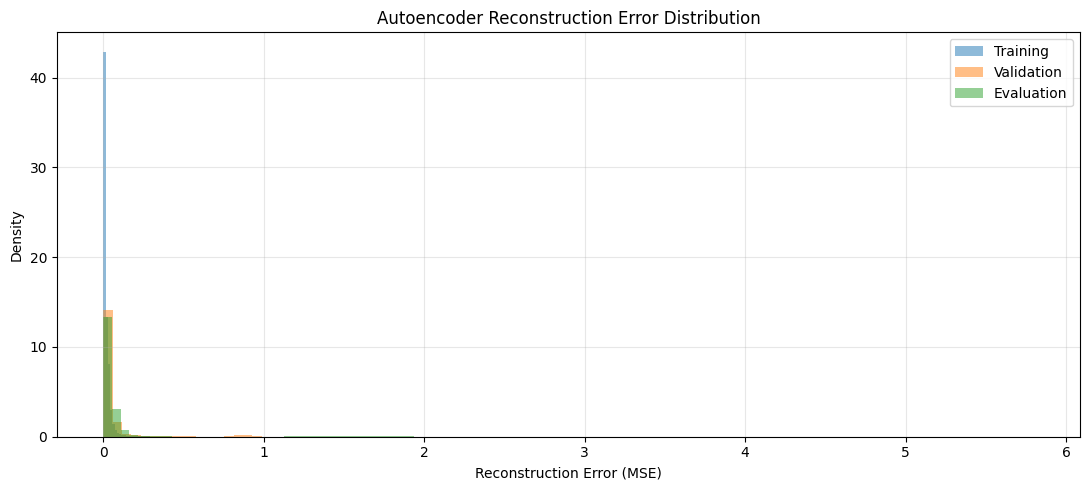

<Figure size 640x480 with 0 Axes>

In [19]:
#Plot reconstruction error distributions
plt.figure(figsize=(11, 5))

plt.hist(train_errors, bins=100, alpha=0.5,
         density=True, label='Training')

plt.hist(val_errors, bins=100, alpha=0.5,
         density=True, label='Validation')

plt.hist(eval_errors, bins=100, alpha=0.5,
         density=True, label='Evaluation')

plt.xlabel('Reconstruction Error (MSE)')
plt.ylabel('Density')
plt.title('Autoencoder Reconstruction Error Distribution')
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

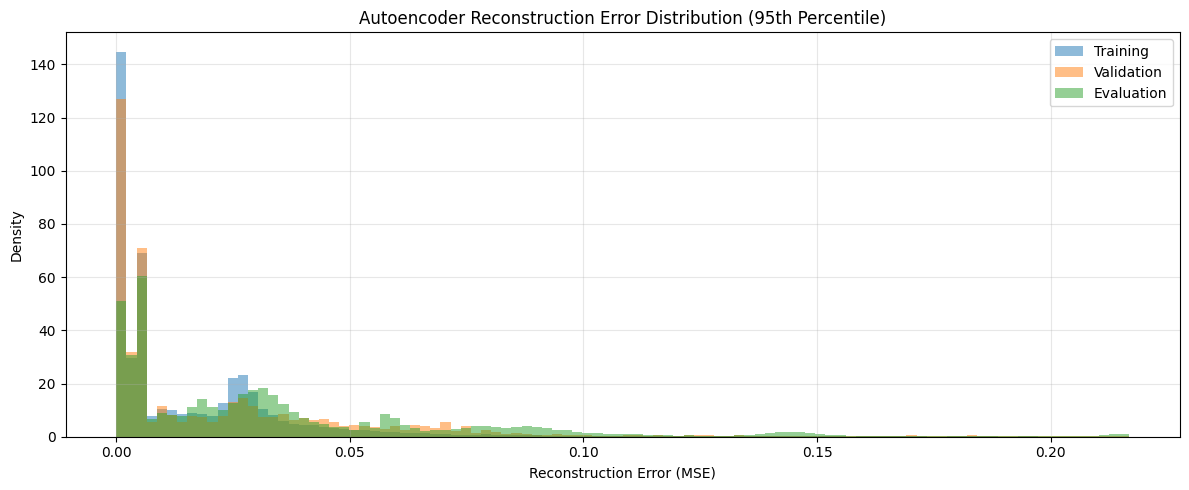

Visualization upper limit: 0.2168


<Figure size 640x480 with 0 Axes>

In [21]:
#Improve the graph
# Calculate a common upper limit for visualization
all_errors = np.concatenate([
    train_errors,
    val_errors,
    eval_errors
])

plot_limit = np.percentile(all_errors, 95)

plt.figure(figsize=(12, 5))

plt.hist(
    train_errors,
    bins=100,
    range=(0, plot_limit),
    alpha=0.5,
    density=True,
    label='Training'
)

plt.hist(
    val_errors,
    bins=100,
    range=(0, plot_limit),
    alpha=0.5,
    density=True,
    label='Validation'
)

plt.hist(
    eval_errors,
    bins=100,
    range=(0, plot_limit),
    alpha=0.5,
    density=True,
    label='Evaluation'
)

plt.xlabel('Reconstruction Error (MSE)')
plt.ylabel('Density')
plt.title('Autoencoder Reconstruction Error Distribution (95th Percentile)')
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

plt.savefig(
    '/content/drive/MyDrive/CAPSTONE_PROJECT/04_autoecoder/Autoencoder_Error_Distribution.png',
    dpi=300,
    bbox_inches='tight'
)

print("Visualization upper limit:", round(plot_limit, 4))

##### OBSERVATIONS:
##### The training dataset has the lowest average reconstruction error, followed by the validation and evaluation datasets.
##### Most reconstruction errors are relatively small, but a few windows have much higher errors.
##### These high values made the original histogram difficult to read.
##### I adjusted the visualization to show the main distribution more clearly.
##### The evaluation errors are generally higher than the training errors,but further analysis is needed to check whether they relate to failures.